In [ ]:
# Hosted D2L setup: fetch the exact helper module used to build this notebook.
from pathlib import Path
from urllib.request import urlretrieve
from importlib.metadata import PackageNotFoundError, version
import importlib.util, os, subprocess, sys

required = ['numpy', 'pandas', 'matplotlib', 'requests', 'scipy', 'pillow', 'regex', 'jax', 'jaxlib', 'flax', 'optax', 'orbax-checkpoint', 'tensorflow', 'protobuf', 'ml-dtypes']
imports = {'pillow': 'PIL', 'orbax-checkpoint': 'orbax', 'protobuf': 'google.protobuf', 'ml-dtypes': 'ml_dtypes'}
pinned = {'jax': ('0.12.0.1', 'jax==0.12.0.1', 'jax[cuda12]==0.12.0.1', 'exact'), 'jaxlib': ('0.12.0.1', 'jaxlib==0.12.0.1', 'jaxlib==0.12.0.1', 'exact'), 'flax': ('0.12.12', 'flax==0.12.12', 'flax==0.12.12', 'exact'), 'optax': ('0.2.8', 'optax==0.2.8', 'optax==0.2.8', 'exact'), 'orbax-checkpoint': ('0.12.0', 'orbax-checkpoint==0.12.0', 'orbax-checkpoint==0.12.0', 'exact')}
fallbacks = {'tensorflow': 'tensorflow==2.21.0', 'protobuf': 'protobuf==7.34.1', 'ml-dtypes': 'ml-dtypes==0.5.4'}
device = os.environ.get("D2L_HOSTED_DEVICE", "auto").lower()
if device not in ("auto", "cpu", "gpu"):
    raise ValueError(f"Invalid D2L_HOSTED_DEVICE={device!r}")
if device == "auto":
    try:
        gpu = (Path("/dev/nvidia0").exists() or
               subprocess.run(["nvidia-smi", "-L"], capture_output=True,
                              timeout=5).returncode == 0)
    except (FileNotFoundError, subprocess.SubprocessError):
        gpu = False
else:
    gpu = device == "gpu"
if not gpu:
    os.environ.setdefault("CUDA_VISIBLE_DEVICES", "-1")
    os.environ.setdefault("JAX_PLATFORMS", "cpu")
tensorflow_version = None
if 'jax' in ("tensorflow", "jax"):
    try:
        tensorflow_version = version("tensorflow")
    except PackageNotFoundError:
        pass
# Colab's CPU image currently carries a CUDA-enabled TensorFlow wheel. Its
# first ordinary tensor operation probes CUDA and emits an error-level cuInit
# diagnostic. JAX notebooks also use TensorFlow for data loading, so overlay
# the matching CPU build in both CPU variants. Keep the provider's
# ``tensorflow`` distribution metadata: other preinstalled Colab packages
# depend on that distribution name, while both wheels expose the same module.
if not gpu and 'jax' in ("tensorflow", "jax"):
    try:
        tensorflow_cpu_version = version("tensorflow-cpu")
    except PackageNotFoundError:
        tensorflow_cpu_version = None
    if (tensorflow_version is not None and
            tensorflow_cpu_version != tensorflow_version):
        subprocess.check_call([
            sys.executable, "-m", "pip", "install", "-q", "--no-deps",
            f"tensorflow-cpu=={tensorflow_version}",
        ])
if "tf-keras" in fallbacks and tensorflow_version is not None:
    fallbacks["tf-keras"] = f"tf-keras=={tensorflow_version}"
missing = []
for package in required:
    if package in pinned:
        wanted, cpu_requirement, gpu_requirement, match = pinned[package]
        requirement = gpu_requirement if gpu else cpu_requirement
        if requirement is None:  # a GPU-only package on a CPU runtime
            continue
        try:
            installed = version(package)
        except PackageNotFoundError:
            installed = None
        actual = (installed.split("+", 1)[0]
                  if installed is not None and match == "public" else installed)
        if actual != wanted:
            missing.append(requirement)
    elif importlib.util.find_spec(imports.get(package, package)) is None:
        missing.append(fallbacks.get(package, package))
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

mismatched = []
for package, (wanted, cpu_requirement, _, match) in pinned.items():
    if not gpu and cpu_requirement is None:
        continue
    try:
        installed = version(package)
    except PackageNotFoundError:
        installed = None
    actual = (installed.split("+", 1)[0]
              if installed is not None and match == "public" else installed)
    if actual != wanted:
        mismatched.append(f"{package}={installed!r} (expected {wanted})")
if mismatched:
    raise RuntimeError("Hosted runtime setup failed: " + ", ".join(mismatched))

root = Path(".d2l-hosted") / "46d487bb9b699b97c7c5fc5edd866e4d2ad7919b"
package = root / "d2l"
package.mkdir(parents=True, exist_ok=True)
base = "https://raw.githubusercontent.com/smolix/d2l-neu/46d487bb9b699b97c7c5fc5edd866e4d2ad7919b/d2l"
for name in ('__init__.py', 'jax.py'):
    target = package / name
    if not target.exists():
        urlretrieve(f"{base}/{name}", target)
if str(root.resolve()) not in sys.path:
    sys.path.insert(0, str(root.resolve()))
pythonpath = os.environ.get("PYTHONPATH", "").split(os.pathsep)
if str(root.resolve()) not in pythonpath:
    os.environ["PYTHONPATH"] = os.pathsep.join(
        [str(root.resolve()), *[entry for entry in pythonpath if entry]]
    )


# Queries, Keys, and Values

A recurrent neural network (that section) compresses everything it has
read into a fixed-size state vector before knowing which details a later
prediction will require. For example, a recurrent model with hidden dimension
768 reading 1,024 tokens must summarize all 1,024 positions in 768 numbers.

A database avoids premature compression by storing records verbatim and
deciding what to retrieve only when a query arrives. However, an exact
database lookup is discontinuous: given key--value pairs
$\mathcal{D}=\{(2,10),(5,20)\}$, the exact query $q=5$ returns $20$, whereas
$q=4$ matches no key. To train with gradient descent, we replace hard lookup
with a *soft* lookup that scores every key—say, by negative squared distance
$a(q,k)=-(q-k)^2$—and converts the scores into convex weights via a softmax.
At $q=4$, the scores for keys $2$ and $5$ are $-4$ and $-1$, giving weights
$e^{-4}/(e^{-4}+e^{-1}) \approx 0.05$ and $0.95$, and a weighted value
$0.05 \cdot 10 + 0.95 \cdot 20 \approx 19.5$. The output varies smoothly
with the query, scales to any number of stored records, and requires no
fixed-size bottleneck prior to querying.

This differentiable key--value lookup is the *attention mechanism*
[@Bahdanau.Cho.Bengio.2014]. We first formulate attention pooling for
vector queries, keys, and values, and then examine its classical
nonparametric precursor, Nadaraya--Watson kernel regression, where a single
bandwidth parameter controls the sharpness of the lookup.

In [1]:
import math
import numpy as np
import jax
from jax import numpy as jnp
from flax import nnx
import optax
from d2l import jax as d2l

## Attention as Differentiable Lookup

Let $\mathcal{D} \stackrel{\textrm{def}}{=} \{(\mathbf{k}_1, \mathbf{v}_1),
\ldots, (\mathbf{k}_m, \mathbf{v}_m)\}$ be a database of $m$ key--value pairs
with keys $\mathbf{k}_i \in \mathbb{R}^{d}$ and values $\mathbf{v}_i \in
\mathbb{R}^{d_v}$. Given a query $\mathbf{q} \in \mathbb{R}^{d}$, *attention
pooling* returns a weighted sum of the values:

$$\textrm{Attention}(\mathbf{q}, \mathcal{D}) \stackrel{\textrm{def}}{=} \sum_{i=1}^m \alpha(\mathbf{q}, \mathbf{k}_i) \mathbf{v}_i,$$

where $\alpha(\mathbf{q},\mathbf{k}_i) \ge 0$ and $\sum_{i=1}^m
\alpha(\mathbf{q},\mathbf{k}_i) = 1$. The output is therefore a convex
combination of the values, interpolating between exact lookup (a one-hot
weight vector) and average pooling (uniform weights $1/m$).

To map arbitrary real-valued compatibility scores $a(\mathbf{q},
\mathbf{k}_i)$ to convex weights, we apply the softmax function
(that section):

$$\alpha(\mathbf{q}, \mathbf{k}_i) = \frac{\exp(a(\mathbf{q}, \mathbf{k}_i))}{\sum_j \exp(a(\mathbf{q}, \mathbf{k}_j))}.$$

Because $\alpha_i = 1 / \big(1 + \sum_{j \neq i} e^{a_j - a_i}\big)$, the
weights depend only on score differences $a_j - a_i$ and are invariant to
adding a constant across all keys. Both the softmax and the linear
combination are differentiable with respect to $\mathbf{q}$, $\mathbf{k}_i$,
and $\mathbf{v}_i$.

As a concrete vector example, take $a(\mathbf{q}, \mathbf{k}) = -\|\mathbf{q}
- \mathbf{k}\|^2$ with query $\mathbf{q} = (1, 1)$, keys $\mathbf{k}_1 = (1,
1)$, $\mathbf{k}_2 = (2, 1)$, $\mathbf{k}_3 = (0, 0)$, and values
$\mathbf{v}_1 = (1, 3)$, $\mathbf{v}_2 = (0, 0)$, $\mathbf{v}_3 = (4, 1)$.
The scores are $0$, $-1$, and $-2$, yielding softmax weights
$(1, e^{-1}, e^{-2}) / (1 + e^{-1} + e^{-2}) \approx (0.67, 0.24, 0.09)$ and
output

$$\mathbf{o} = 0.67\,(1, 3) + 0.24\,(0, 0) + 0.09\,(4, 1) \approx (1.0, 2.1).$$

Notice two properties illustrated in the figure. First, even though
$\mathbf{k}_1$ matches $\mathbf{q}$ exactly, it receives only two-thirds of
the weight; scaling the scores by a factor of $10$ (to $0, -10, -20$)
concentrates $99.995\%$ of the weight on $\mathbf{k}_1$. Thus the magnitude
of the scores governs how sharply the softmax commits. Second, although
$\mathbf{v}_2 = (0, 0)$ adds zero to the sum, its $0.24$ weight still pulls
the output toward the origin by diluting the other values.

![Soft lookup of the query $\mathbf{q} = (1, 1)$ in three key--value pairs, with keys $(1, 1)$, $(2, 1)$, $(0, 0)$ and values $(1, 3)$, $(0, 0)$, $(4, 1)$. The scores $s_i = -\|\mathbf{q} - \mathbf{k}_i\|^2$ become softmax weights $\alpha_i$ that sum to one (left), and the output $\mathbf{o} \approx (1.0, 2.1)$ is the weighted sum of the values, a point inside the triangle whose corners are the values (right).](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/mdl-attention-soft-lookup.svg)

The attention rule the equation applies unchanged to any
number of records $m$, allowing a single layer to process sequences of
arbitrary length without compressing them into a fixed-size state. The cost
shifts to memory: whereas a recurrent layer of width 768 keeps 768 numbers,
one 12-head attention layer of GPT-2 small ($d = 64$ per head) over 1,024
tokens stores $2 \times 1{,}024 \times 64 = 131{,}072$ key and value entries
per head, or roughly $1.6 \times 10^6$ numbers across all 12 heads.

## Attention Pooling with Fixed Kernels

Long before deep learning, *Nadaraya--Watson kernel regression*
[@Nadaraya.1964; @Watson.1964] used the equation for
nonparametric regression, treating training inputs as keys, training labels
as values, and a fixed similarity kernel as the scoring rule.

### Kernels and the Nadaraya--Watson Estimator

Given a nonnegative similarity kernel $K(\mathbf{q}, \mathbf{k})$, such as
the Gaussian kernel with *bandwidth* $\sigma > 0$,

$$K(\mathbf{q}, \mathbf{k}) = \exp\left(-\frac{\|\mathbf{q} - \mathbf{k}\|^2}{2\sigma^2}\right),$$

normalizing across keys yields the *Nadaraya--Watson estimator*:

$$f(\mathbf{q}) = \sum_i \mathbf{v}_i \frac{K(\mathbf{q}, \mathbf{k}_i)}{\sum_j K(\mathbf{q}, \mathbf{k}_j)}.$$

For any strictly positive kernel, the equation is softmax
attention the equation with score $a(\mathbf{q}, \mathbf{k})
= \log K(\mathbf{q}, \mathbf{k})$. For the Gaussian kernel, $a(\mathbf{q},
\mathbf{k}) = -\|\mathbf{q} - \mathbf{k}\|^2 / (2\sigma^2)$, which recovers
our opening example when $2\sigma^2 = 1$. Under regularity conditions on the
density and target function, as $m \to \infty$ and $\sigma \to 0$ at an
appropriate rate, $f(\mathbf{q})$ converges to the conditional expectation
$\mathbb{E}[y \mid \mathbf{q}]$ [@mack1982weak].

### The Bandwidth

To see how the bandwidth $\sigma$ controls the estimator, we draw $n = 40$
noisy training observations from $y = 2\sin(x) + x + \epsilon$ with $\epsilon
\sim \mathcal{N}(0, 1)$ on $[0, 5)$ and evaluate predictions on a dense grid.

In [2]:
n = 40
x_train = jnp.sort(jax.random.uniform(d2l.get_key(), (n,)) * 5)
y_train = (2 * jnp.sin(x_train) + x_train
           + jax.random.normal(d2l.get_key(), (n,)))
x_val = jnp.arange(0, 5, 0.1)
y_val = 2 * jnp.sin(x_val) + x_val

The implementation computes all pairwise query--key distances, evaluates the
Gaussian kernel, normalizes each query row, and multiplies by `y_train`.

In [3]:
def nadaraya_watson(x_train, y_train, x_val, sigma):
    dists = x_val[:, None] - x_train[None, :]  # (queries, keys)
    k = d2l.exp(-dists**2 / (2 * sigma**2))
    attention_w = k / k.sum(1, keepdims=True)  # Normalize over the keys
    return attention_w @ y_train, attention_w

As $\sigma \to 0$, all weight concentrates on the nearest training point
(1-nearest-neighbor interpolation); as $\sigma \to \infty$, all weights
approach $1/n$ (the global sample mean). We plot $\sigma \in \{0.1, 0.5,
2.0\}$ below.

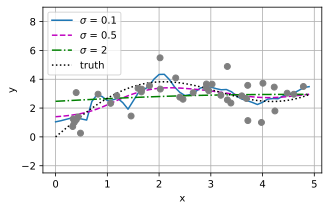

In [4]:
sigmas = (0.1, 0.5, 2.0)
estimates = [nadaraya_watson(x_train, y_train, x_val, s)[0] for s in sigmas]
d2l.plot([x_val] * 4 + [x_train], estimates + [y_val, y_train], 'x', 'y',
         legend=[rf'$\sigma$ = {s:g}' for s in sigmas] + ['truth'],
         fmts=('-', 'm--', 'g-.', 'k:', 'C7o'), ylim=(-2.5, 9),
         figsize=(5, 3), legend_loc='upper left')

A narrow bandwidth ($\sigma = 0.1$) overfits individual noisy labels, while a
wide bandwidth ($\sigma = 2.0$) oversmooths toward a horizontal line. The
intermediate value $\sigma = 0.5$ tracks the true curve closely except near
the boundaries, where all neighbors lie on one side. In practice $\sigma$ can
be chosen by leave-one-out cross-validation, which requires only zeroing the
diagonal of the weight matrix and renormalizing its rows (Exercise
5).

More broadly, $1/\sigma^2$ acts as an inverse temperature multiplying the
raw scores $-\tfrac{1}{2}(q - k)^2$ before the softmax. Scaling scores up
stretches pairwise gaps and drives the softmax toward a one-hot lookup;
scaling scores down compresses gaps and drives the softmax toward uniform
averaging. We will see this same temperature scaling in dot-product attention
(that section).

## Attention Weights as a Diagnostic

Because each row of the attention matrix $\mathbf{A}$ is a probability
distribution over keys, plotting $\mathbf{A}$ as a heatmap shows which keys
each query consults.

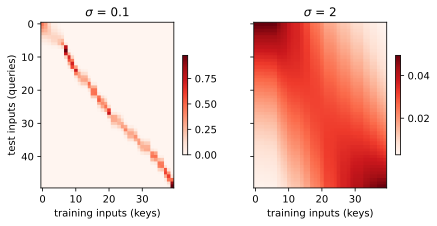

In [5]:
w_narrow, w_wide = (nadaraya_watson(x_train, y_train, x_val, s)[1]
                    for s in (0.1, 2.0))
# show_heatmaps takes (rows of panels, columns of panels, queries, keys)
d2l.show_heatmaps(d2l.stack([w_narrow, w_wide])[None],
                  xlabel='training inputs (keys)',
                  ylabel='test inputs (queries)',
                  titles=[r'$\sigma$ = 0.1', r'$\sigma$ = 2'],
                  figsize=(7, 3), cbar='each')

At $\sigma = 0.1$, weight concentrates in a narrow diagonal band around the
nearest training inputs; at $\sigma = 2.0$, weight spreads broadly across the
dataset: every weight stays within a factor of about two of the uniform value
$1/40 = 0.025$, and the largest, about $0.05$, belong to queries at the edges.

Two caveats apply when inspecting attention heatmaps in deep networks:

1. **Weights show where a layer looks, not what it transmits:** A key can
   receive a large attention weight even if its value vector is zero (as with
   $\mathbf{v}_2 = (0, 0)$ in our vector example) or lies in the null space
   of downstream projections. Verifying a head's causal role requires
   interventional experiments (that section).
2. **Fixed kernels enforce a static similarity metric:** In
   the equation, every query uses the same Euclidean distance
   in input space. In sequence modeling, however, relevance is context- and
   task-dependent—a verb may need its syntactic subject several tokens away.
   Learned attention layers therefore project inputs into trainable query,
   key, and value spaces before scoring.

## Summary

Attention pooling computes a convex combination of value vectors $\sum_i \alpha(\mathbf{q}, \mathbf{k}_i)\mathbf{v}_i$, whose softmax weights $\alpha(\mathbf{q}, \mathbf{k}_i)$ interpolate smoothly between exact dictionary lookup and uniform average pooling. Unlike a fixed-size recurrent state, attention accesses all stored key–value pairs directly using a rule independent of the number of pairs $m$, while working memory grows linearly with $m$. Nadaraya–Watson kernel regression corresponds to attention pooling with a fixed Euclidean similarity kernel whose bandwidth $\sigma$ acts as a softmax temperature governing the bias–variance trade-off. Although attention heatmaps visualize query–key alignments, moving beyond fixed input-space distance requires trainable projections and learned scoring functions.

## Exercises

1. **An average of two values.** Let the keys $\mathbf{k}_1, \ldots,
   \mathbf{k}_m$ be orthonormal and let the score be $a(\mathbf{q},
   \mathbf{k}) = \mathbf{q}^\top \mathbf{k}$ with the weights
   of the equation.
    1. For the query $\mathbf{q} = c\,(\mathbf{k}_a + \mathbf{k}_b)$ with
       $c > 0$, compute all $m$ weights and show that the output tends to
       $\tfrac{1}{2}(\mathbf{v}_a + \mathbf{v}_b)$ as $c \to \infty$.
    1. How large must $c$ be for the two selected keys to receive at least
       99% of the total weight when $m = 10$?
    1. Now let the keys be orthogonal with $\|\mathbf{k}_b\| =
       2\,\|\mathbf{k}_a\|$. Find a query that again averages
       $\mathbf{v}_a$ and $\mathbf{v}_b$, and state what
       $\mathbf{q} = c\,(\mathbf{k}_a + \mathbf{k}_b)$ returns instead as
       $c \to \infty$.

    *Adapted from Stanford CS224N,
    [Assignment 4](https://web.stanford.edu/class/cs224n/assignments_w25/a4.pdf),
    Problems 1(b) and 1(c).*

1. [code] **Effective number of keys.** For the weights $\alpha_i(q)$ of
   one query, define the effective number of keys
   $n_{\textrm{eff}}(q) = 1 / \sum_i \alpha_i(q)^2$.
    1. Let the values be $y_i = g(x_i) + \epsilon_i$ with independent noise
       of variance $s^2$, and hold the keys fixed. Show that the variance of
       the estimate the equation at $q$ is
       $s^2 / n_{\textrm{eff}}(q)$.
    1. Compute $n_{\textrm{eff}}$ at every query in `x_val` from the weights
       that `nadaraya_watson` returns, for each bandwidth in `sigmas`, and
       plot the three curves. Then redraw the noise in `y_train` 200 times
       with `x_train` fixed, and compare the standard deviation of the
       estimate at each query with $1 / \sqrt{n_{\textrm{eff}}(q)}$.

1. [code] **The gradient of attention.** ● Suppose that $a(\mathbf{q},
   \mathbf{k}_i) = \mathbf{q}^\top \mathbf{k}_i$ and that $\mathbf{k}_i =
   \mathbf{v}_i$ for $i = 1, \ldots, m$. Denote by $p(\mathbf{k}_i;
   \mathbf{q})$ the distribution over keys defined by the softmax
   normalization the equation.
    1. Prove that
       $$\nabla_{\mathbf{q}} \mathop{\textrm{Attention}}(\mathbf{q}, \mathcal{D}) = \textrm{Cov}_{p(\mathbf{k}_i; \mathbf{q})}[\mathbf{k}_i].$$
    1. Conclude that this Jacobian is positive semidefinite, and determine
       for which databases it is the zero matrix.
    1. Let $\mathbf{q} = c\,\mathbf{u}$ for a fixed direction $\mathbf{u}$
       for which exactly one key attains the largest score
       $\mathbf{u}^\top \mathbf{k}_i$. Find the limit of the Jacobian as
       $c \to \infty$, and state what it implies for training the query by
       gradient descent.
    1. Verify the identity and the limit with automatic differentiation on
       a random database with $m = 8$ and $d = 4$.

1. [code] **Soft lookup as retrieval.** ● Build a database of $m$ keys
   drawn uniformly from the unit sphere in $\mathbb{R}^{16}$, with value
   $\mathbf{v}_i$ the one-hot indicator of index $i$, and weight them with
   the Gaussian kernel of bandwidth $\sigma$ normalized as
   in the equation, so that the output is the vector of
   weights. Query with a noisy copy $\mathbf{q} = \mathbf{k}_i +
   \boldsymbol{\epsilon}$ of a stored key, with $\boldsymbol{\epsilon} \sim
   \mathcal{N}(\mathbf{0}, \tau^2 \mathbf{I})$.
    1. Show that the largest weight goes to the key nearest the query for
       every $\sigma > 0$, so the bandwidth does not affect which index
       wins. It does affect how much of the weight the winner takes.
    1. Without noise, the weight on the correct key is
       $$\alpha_i = \frac{1}{1 + \sum_{j \neq i} \exp\big(-\|\mathbf{k}_i - \mathbf{k}_j\|^2 / 2\sigma^2\big)}.$$
       Approximate $\mathbf{k}_i^\top \mathbf{k}_j \approx 0$ for random
       unit vectors, so that $\|\mathbf{k}_i - \mathbf{k}_j\|^2 \approx 2$,
       and derive the bandwidth at which $\alpha_i$ falls to $0.9$ for
       $m = 20$ and for $m = 200$. How must $\sigma$ shrink as $m$ grows?
    1. A lookup whose output the next layer can use needs most of the
       weight on one key, not merely the largest share. Call the query
       retrieved when $\alpha_i \geq 0.5$. Sweep $\tau$ from $0$ to $1$ at
       $m = 20$ and $m = 200$, with the bandwidth from (b) for each $m$,
       and plot the retrieval accuracy against $\tau$. Compute the weights as the softmax
       the equation of the scores
       $-\|\mathbf{q} - \mathbf{k}_j\|^2 / 2\sigma^2$. Explain why a larger
       $m$ lowers the accuracy at fixed $\tau$ although the distance from
       the query to the correct key is unchanged.

1. [extended] **A learned metric.** ● Kernel regression with a learned
   distance [@Weinberger.Tesauro.2007] replaces the fixed similarity
   of the equation by a learned one. Draw $n = 200$ inputs
   $\mathbf{x}_i$ uniformly from $[0, 5]^5$ and labels $y_i =
   2\sin(x_{i1}) + x_{i1} + \epsilon_i$ with standard Gaussian noise, so
   that only the first coordinate matters. Score a query against a key by
   $$a(\mathbf{q}, \mathbf{k}) = -\tfrac{1}{2} \|\mathbf{W}(\mathbf{q} - \mathbf{k})\|^2, \qquad \mathbf{W} = \textrm{diag}(w_1, \ldots, w_5),$$
   normalize as in the equation, and fit $\mathbf{W}$ to
   the leave-one-out error, in which the estimate at $\mathbf{x}_i$
   excludes the pair $(\mathbf{x}_i, y_i)$. Measure the test error on
   $1000$ fresh inputs against the noise-free function.
    1. Fit the isotropic kernel $w_1 = \cdots = w_5 = 1/\sigma$ by a grid
       search over $\sigma$.
    1. Starting from the isotropic solution, fit the five scales by gradient
       descent. Compare the learned scales with the relevance of each
       coordinate, and the test error with that of the isotropic kernel and
       of an oracle that uses only the first coordinate at its best
       bandwidth.
    1. Compare the leave-one-out errors of the learned and the oracle
       metrics with their test errors, and repeat the comparison at
       $n = 1000$. What does the result say about learning a similarity from
       a finite sample?
    1. A full matrix $\mathbf{W} \in \mathbb{R}^{5 \times 5}$ maps queries
       and keys by the same linear map, whereas learned attention maps them
       by separate matrices $\mathbf{W}_q$ and $\mathbf{W}_k$. State two
       properties of the score $a$ that the shared map guarantees and
       separate maps lose.

[Discussions](https://d2l.discourse.group/t/36768)